In [1]:
import uproot
import hist
import mplhep
mplhep.style.use("ROOT")
import matplotlib.pyplot as plt

In [3]:
# skip first event when all of the memory is being allocated and such
with uproot.open('ldmx-sw-vers-bump/performance-log.root') as f:
    s = f['performance/by_event'].arrays(entry_start=1)

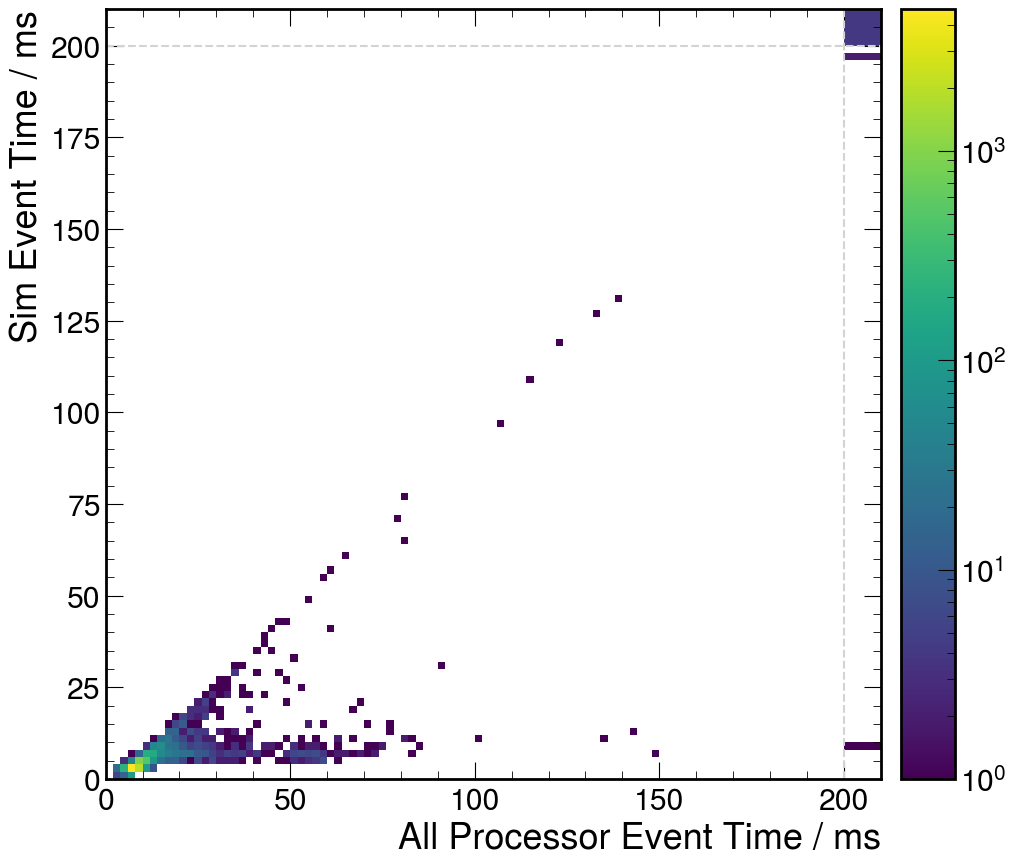

In [4]:
time_h = (
    hist.Hist.new
    .Reg(100,0,200, name="all", label='All Processor Event Time / ms')
    .Reg(100,0,200, name="sim", label='Sim Event Time / ms')
    .Double()
)
time_h.fill(
    sim = s["sim.duration_"]*1000,
    all = s["__ALL__.duration_"]*1000,
)
time_h.plot(norm='log', flow='show')
plt.show()

In [5]:
sim_frac_h = hist.Hist.new.Reg(100,0,1,label='Sim Time Fraction').Double()
sim_frac_h.fill(s["sim.duration_"]/s["__ALL__.duration_"])

Hist(Regular(100, 0, 1, label='Sim Time Fraction'), storage=Double()) # Sum: 9999.0

[StairsArtists(stairs=<matplotlib.patches.StepPatch object at 0x7822540ad790>, errorbar=None, legend_artist=None)]

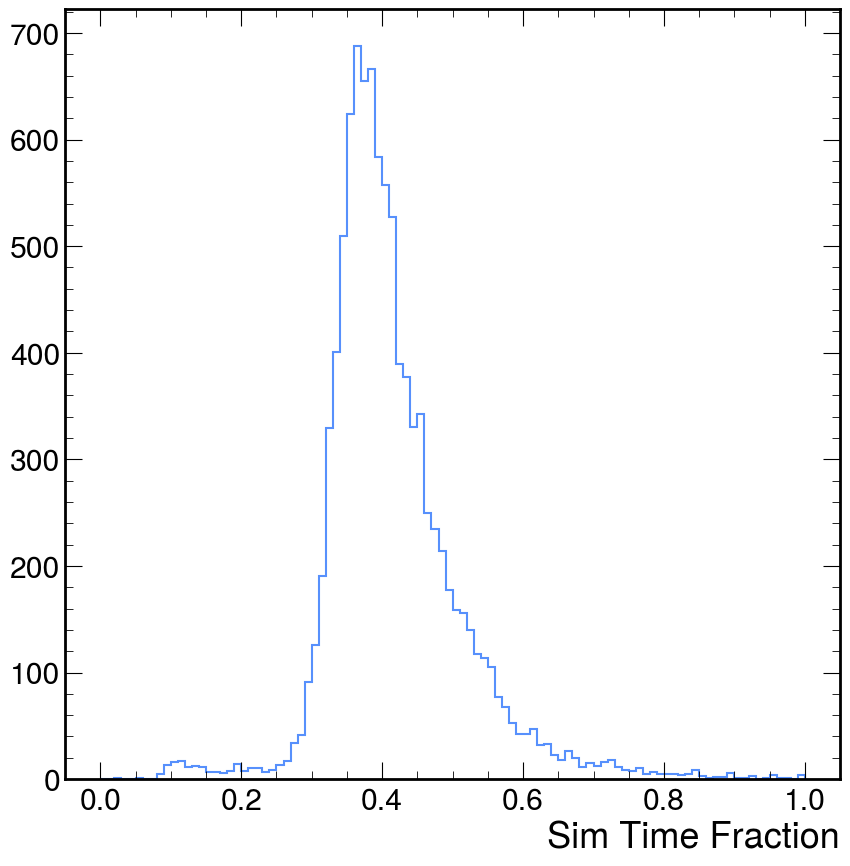

In [6]:
sim_frac_h.plot(yerr=False)

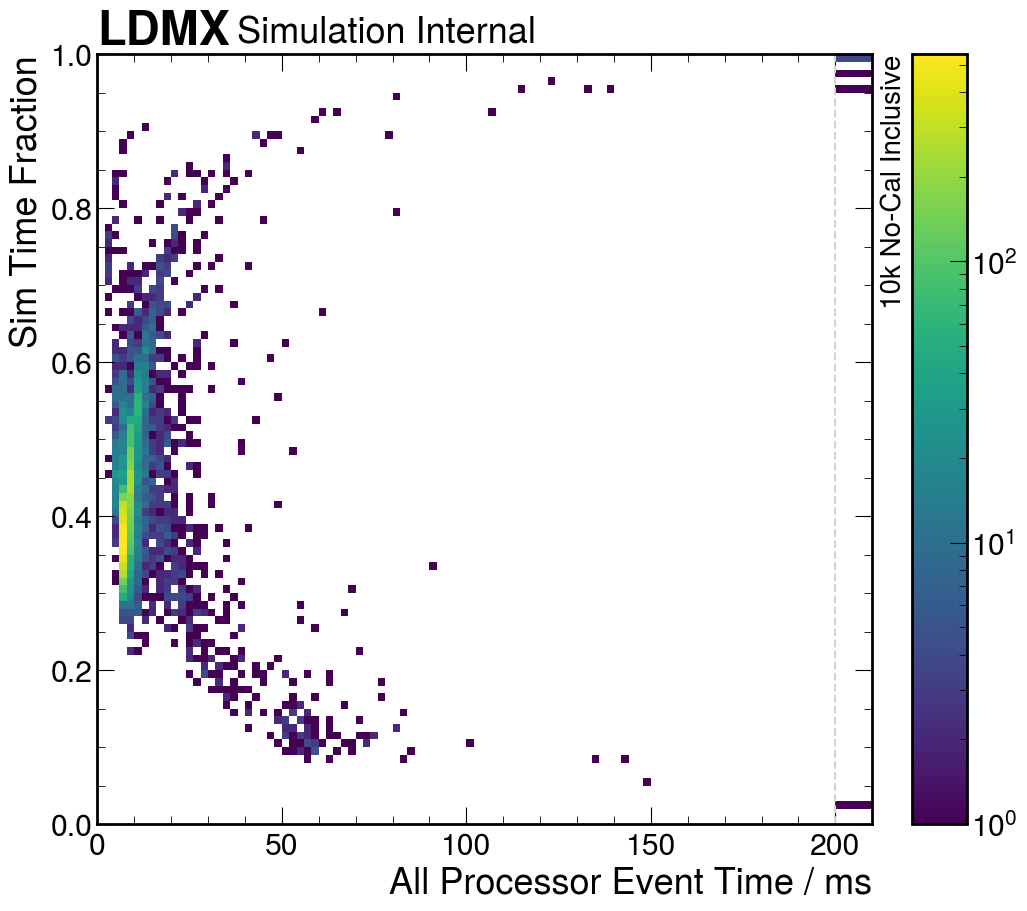

In [17]:
time_h = (
    hist.Hist.new
    .Reg(100,0,200, name="all", label='All Processor Event Time / ms')
    .Reg(100,0,1, name="simfrac", label='Sim Time Fraction')
    .Double()
)
time_h.fill(
    simfrac = s["sim.duration_"]/s["__ALL__.duration_"],
    all = s["__ALL__.duration_"]*1000,
)
time_h.plot(norm='log', flow='show', cbarpad = 0.4)
mplhep.label.exp_text("LDMX", "Simulation Internal", "10k No-Cal Inclusive")
plt.show()